<a href="https://colab.research.google.com/github/ancestor9/2026_Spring_Capstone-Design/blob/main/week5/seminar_note_8_1_model_agnostic_interpretability_(eXAI).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Model Interpretability**

In [1]:
from IPython.core.interactiveshell import InteractiveShell # 모든 명령어 출력
InteractiveShell.ast_node_interactivity = 'all'
import warnings # 파이썬 버전에 따른 오류 출력 방지
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

In [50]:
# from sklearn.datasets import load_breast_cancer///
from sklearn.model_selection import train_test_split
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns= data.feature_names)
y = data.target
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=11)

In [51]:
from sklearn.linear_model import LogisticRegression
lgr = LogisticRegression()
lgr.fit(X_train, y_train)

lgr.coef_

LogisticRegression()

array([[ 1.06603782,  0.5106579 ,  0.26254745, -0.02003388, -0.03904023,
        -0.18406235, -0.26089646, -0.11020129, -0.05254886, -0.01073547,
         0.04404536,  0.4277785 ,  0.20094997, -0.13135285, -0.00394351,
        -0.04135345, -0.05320051, -0.013387  , -0.01151143, -0.00411242,
         1.1203008 , -0.555864  , -0.27277449, -0.00890936, -0.07434959,
        -0.55873555, -0.68476713, -0.19889154, -0.1575599 , -0.05343556]])

In [52]:
data = zip(X_train.columns, np.squeeze(lgr.coef_))
df_coef = pd.DataFrame(data, columns=['variable', 'coefficient'])
df_coef.head()

,variable,coefficient
0,mean radius,1.066038
1,mean texture,0.510658
2,mean perimeter,0.262547
3,mean area,-0.020034
4,mean smoothness,-0.039040


In [53]:
df_coef_sorted = df_coef.sort_values(by='coefficient', ascending=False)
df_coef_sorted.head()

,variable,coefficient
20,worst radius,1.120301
0,mean radius,1.066038
1,mean texture,0.510658
11,texture error,0.427778
2,mean perimeter,0.262547


In [54]:
df_coef_sorted.tail()

,variable,coefficient
6,mean concavity,-0.260896
22,worst perimeter,-0.272774
21,worst texture,-0.555864
25,worst compactness,-0.558736
26,worst concavity,-0.684767


<Axes: xlabel='variable'>

Text(0.5, 1.0, 'Feature Importance')

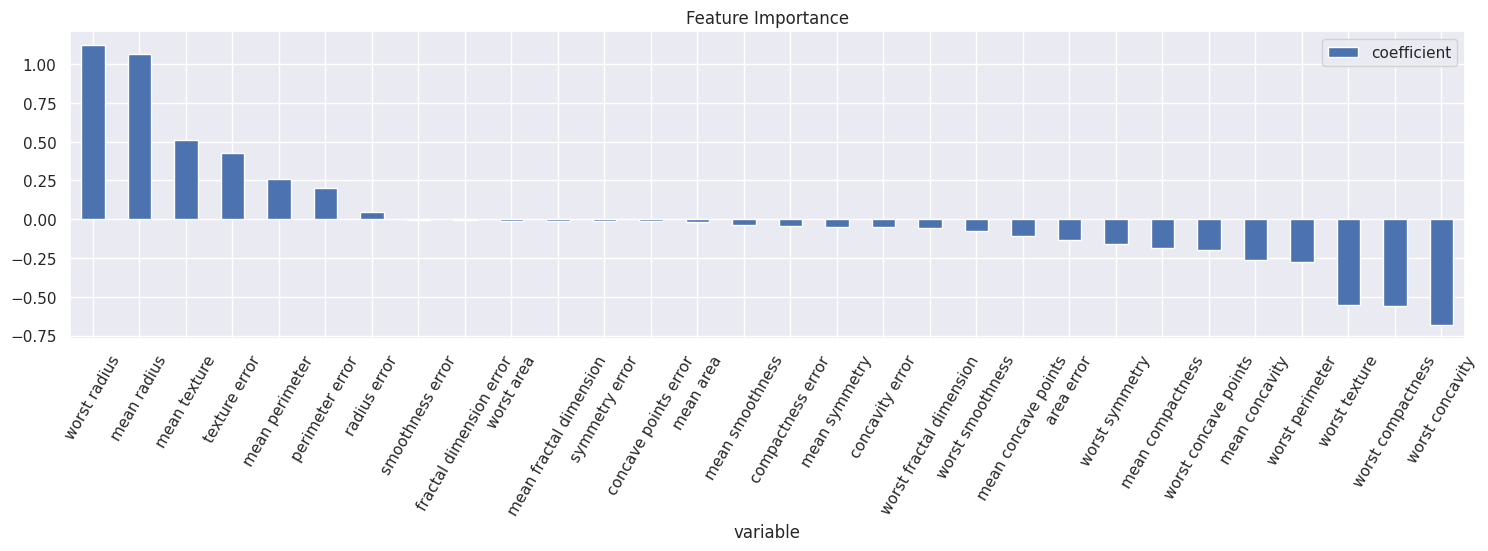

In [55]:
df_coef_sorted.set_index('variable').plot.bar(rot=60, figsize=(18,4))
plt.title('Feature Importance')

## 1. 특성변수 model-based 중요도

랜덤포레스트 모델의 입력변수의 중요도를 X축으로 하여 변수명을 시각화
- '연령’, ‘모바일 평일 이용시간’, ‘모바일 주말 이용시간’ 등이 예측에 크게 영향을 미치고 있다.

RandomForestClassifier(class_weight='balanced')

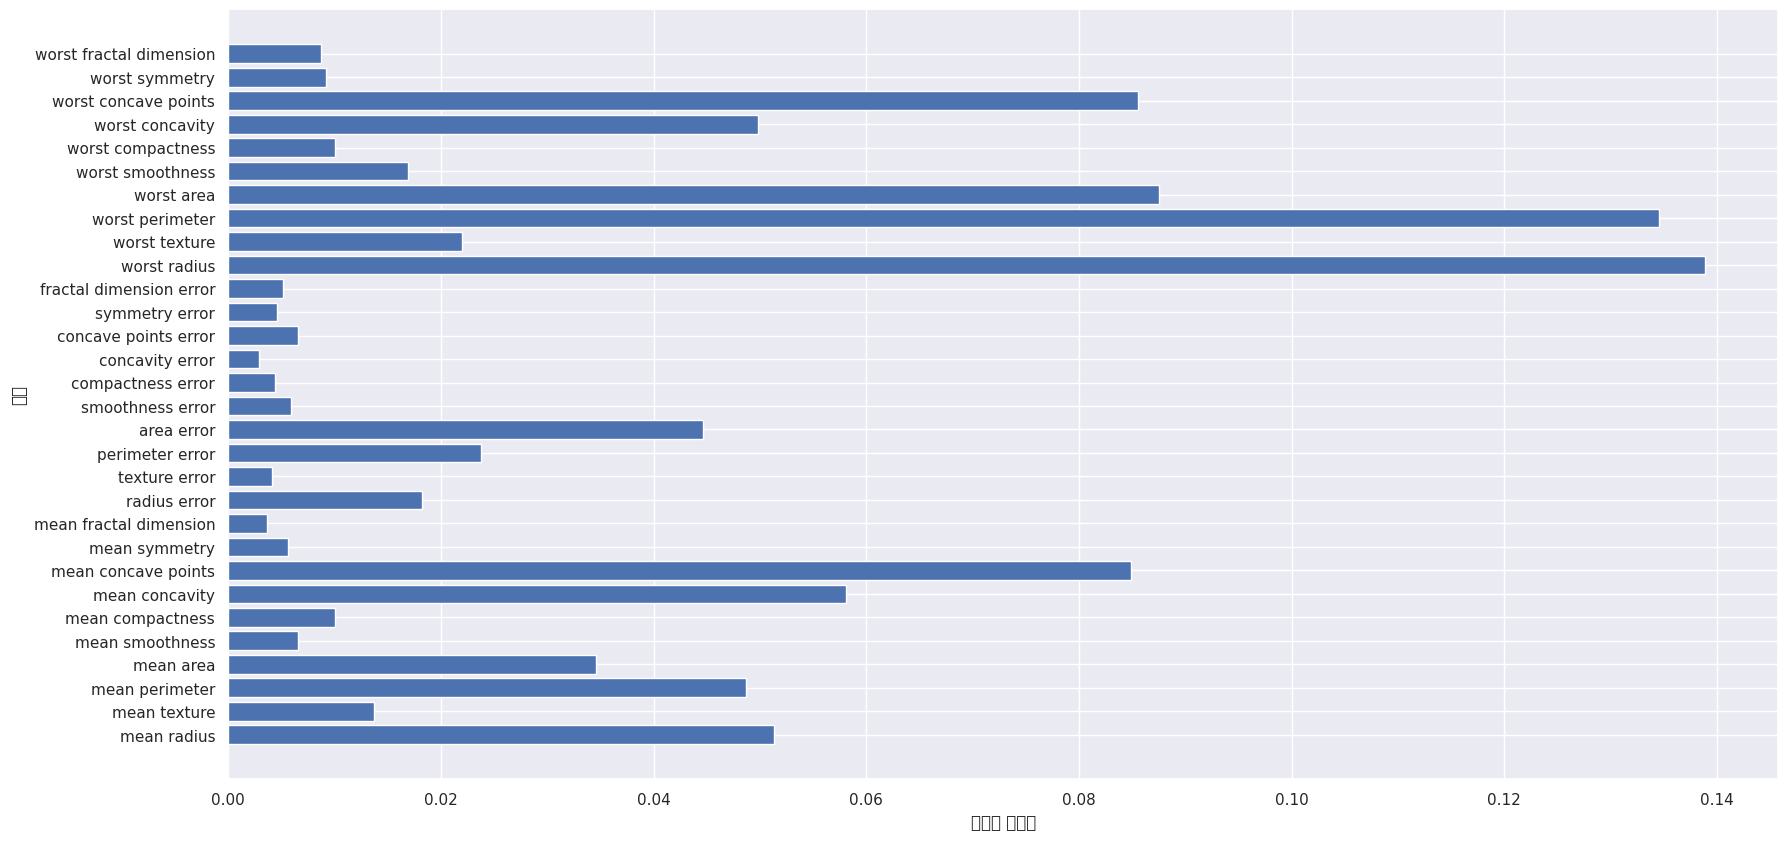

In [56]:
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier)
rf = RandomForestClassifier(class_weight='balanced', n_estimators=100)
rf.fit(X_train, y_train)
def plot_feature_importances(model):
    fig, ax = plt.subplots(1,1,figsize=(20,10))
    plt.barh(range(X_train.shape[1]), rf.feature_importances_, align='center')
    plt.yticks(np.arange(X_train.shape[1]), X_train.columns)
    plt.xlabel('변수의 중요도')
    plt.ylabel('변수')
    #plt.savefig('../../output/Feature_importance') # 그림 파일 저장
plot_feature_importances(rf)

In [57]:
rf.feature_importances_

array([0.0512768 , 0.01371236, 0.04868558, 0.03453276, 0.00656333,
       0.01007085, 0.05808394, 0.0849095 , 0.00556851, 0.00360036,
       0.01816799, 0.00406992, 0.02380272, 0.04467569, 0.00587778,
       0.00442275, 0.0028348 , 0.00650987, 0.00454597, 0.00510785,
       0.13882736, 0.02192569, 0.1345095 , 0.08752104, 0.01688092,
       0.01003647, 0.04984356, 0.0855686 , 0.00914309, 0.00872443])

## 2. 특성변수 permutation-based 중요도

- 특정 변수의 값을 무작위로 재정렬하여(permutation) 학습하는 경우 모델의 정확도에 영향을 얼마나 주는지를 가리키는 지표
     * model_based’ 중요도의 크기와는 다르다. 사이킷런의 Permutation-based feature importance모듈을 호출
- 예측에 영향을 미치는 입력변수의 중요도가 높은 순서대로 확인

<Axes: xlabel='0'>

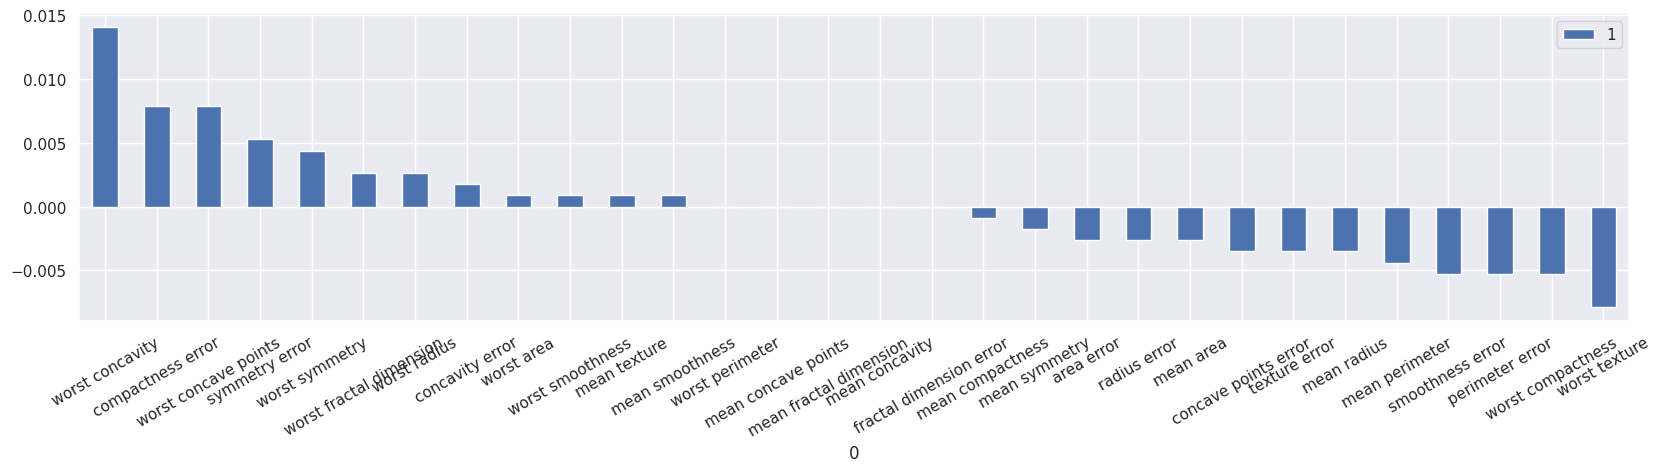

In [58]:
from sklearn.inspection import permutation_importance
result = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=0)
#result.importances_mean.round(4)
#np.argsort(result.importances_mean)
data = pd.DataFrame(list(zip(X_train.columns, result.importances_mean)))
data.sort_values(by =1, ascending= False, inplace =True)
data.plot(kind='bar', x=0, y=1, rot=30, figsize=(20, 4))

## 3. Feature Selection(Scikit-learn)
- 변수 선택(Feature Selection) 기법 중 하나인 RFE(Recursive Feature Elimination, 반복적 변수 제거) 방식을 설정하여 **"가장 쓸모없는 선수부터 하나씩 퇴출시켜서, 마지막까지 살아남는 최고의 선수를 가려내는 서바이벌 오디션"**

- [Recursive feature elimination
](https://scikit-learn.org/stable/auto_examples/feature_selection/plot_rfe_digits.html)

In [71]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# Load the digits dataset
digits = load_digits()
X = digits.images.reshape((len(digits.images), -1))
y = digits.target

pipe = Pipeline(
    [
        ("scaler", MinMaxScaler()),
        ("rfe", RFE(estimator=LogisticRegression(), n_features_to_select=1, step=1)),
    ]
)

pipe.fit(X, y)

Pipeline(steps=[('scaler', MinMaxScaler()),
                ('rfe',
                 RFE(estimator=LogisticRegression(), n_features_to_select=1))])

In [76]:
pipe.named_steps["rfe"].ranking_

array([64, 48, 35, 28, 20, 13, 29, 52, 55, 42,  6, 44, 24, 34, 43, 53, 51,
       46, 18, 14, 10,  4, 37, 57, 54, 41,  3,  9, 19, 26,  8, 56, 63, 27,
       22, 30, 11, 32,  1, 62, 61, 38,  7,  5, 23, 17, 25, 59, 60, 47, 39,
       21, 12, 15, 36, 49, 58, 50, 16, 40, 31,  2, 33, 45])

In [77]:
pipe.named_steps["rfe"].ranking_.reshape(digits.images[0].shape)

array([[64, 48, 35, 28, 20, 13, 29, 52],
       [55, 42,  6, 44, 24, 34, 43, 53],
       [51, 46, 18, 14, 10,  4, 37, 57],
       [54, 41,  3,  9, 19, 26,  8, 56],
       [63, 27, 22, 30, 11, 32,  1, 62],
       [61, 38,  7,  5, 23, 17, 25, 59],
       [60, 47, 39, 21, 12, 15, 36, 49],
       [58, 50, 16, 40, 31,  2, 33, 45]])

<Axes: >

Text(0.5, 1.0, 'Ranking of pixels with RFE (Heatmap)')

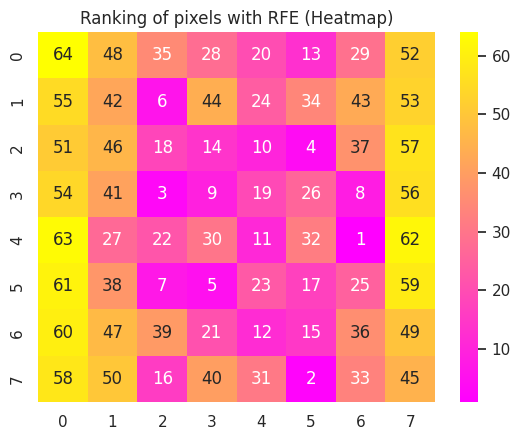

In [86]:
ranking_reshaped = pipe.named_steps["rfe"].ranking_.reshape(digits.images[0].shape)
sns.heatmap(ranking_reshaped, annot=True, fmt="d", cmap='spring', cbar=True)
plt.title("Ranking of pixels with RFE (Heatmap)")
plt.show()

## 4. VarianceThreshold(Scikit-learn)
- [VarianceThreshold](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.VarianceThreshold.html)
- "변화가 없는 데이터 솎아내기"는 모든 샘플에서 값이 거의 변하지 않는(분산이 낮은) 특성을 제거
- 분산이 설정한 임계값(Threshold)보다 낮으면 "정보 가치가 없다"고 판단하여 삭제
- 모든 값이 똑같은 특성(분산 = 0)을 찾아내 삭제합니다.
- 예를 들어 80% 이상이 같은 값인 경우

베르누이 확률 변수(이진 데이터)의 분산불리언(True/False, 0/1) 데이터는 베르누이 분포를 따르며, 분산 계산식은 다음과 같습니다.$$Var[X] = p(1 - p)$$(여기서 $p$는 해당 특성이 1(True)일 확률입니다.)

In [93]:
from sklearn.feature_selection import VarianceThreshold
X = np.array([[0, 0, 1], [0, 1, 0], [1, 0, 0], [0, 1, 1], [0, 1, 0], [0, 1, 1], [0, 1, 1], [0, 1, 1]])
sel = VarianceThreshold(threshold=(.8 * (1 - .8)))
X
sel.fit_transform(X)

array([[0, 0, 1],
       [0, 1, 0],
       [1, 0, 0],
       [0, 1, 1],
       [0, 1, 0],
       [0, 1, 1],
       [0, 1, 1],
       [0, 1, 1]])

array([[0, 1],
       [1, 0],
       [0, 0],
       [1, 1],
       [1, 0],
       [1, 1],
       [1, 1],
       [1, 1]])

In [95]:
np.var(X, 0) # 변수의 분산(p*(1-p))을 구하면

array([0.109375, 0.1875  , 0.234375])

## 5. Entropy


- [Alone in the woods: Using Theil's U for survival](https://www.kaggle.com/code/shakedzy/alone-in-the-woods-using-theil-s-u-for-survival)
- 우리가 흔히 쓰는 '피어슨 상관계수'는 숫자형 데이터에만 쓸 수 있고 직선적인 관계만 찾지만 Theil's U는 다음과 같은 특징

> 범주형 데이터 전용: 성별, 직업, 혈액형 같은 텍스트 데이터 사이의 관계를 찾을 때 탁월

> 비대칭성: "직업을 알면 소득을 알 수 있지만, 소득을 안다고 해서 정확한 직업을 맞히기는 어렵다"와 같은 방향성이 있는 관계를 추출

> **"변수 y가 변수 x에 대해 제공하는 정보의 양"** 을 0~1 사이의 점수로 환산해 주는 도구

In [97]:
import math
import numpy as np
import scipy.stats as ss
from collections import Counter

def conditional_entropy(x,y):
    # entropy of x given y
    y_counter = Counter(y)
    xy_counter = Counter(list(zip(x,y)))
    total_occurrences = sum(y_counter.values())
    entropy = 0
    for xy in xy_counter.keys():
        p_xy = xy_counter[xy] / total_occurrences
        p_y = y_counter[xy[1]] / total_occurrences
        entropy += p_xy * math.log(p_y/p_xy)
    return entropy

def theil_u(x,y):
    s_xy = conditional_entropy(x,y)
    x_counter = Counter(x)
    total_occurrences = sum(x_counter.values())
    p_x = list(map(lambda n: n/total_occurrences, x_counter.values()))
    s_x = ss.entropy(p_x)
    if s_x == 0:
        return 1
    else:
        return (s_x - s_xy) / s_x

In [98]:
# --- 테스트 데이터 ---

# 1. 완벽한 관계 (Weather를 알면 Umbrella를 100% 맞춤)
weather_1 = ['Rain', 'Rain', 'Sun', 'Sun']  # features
umbrella_1 = ['Yes', 'Yes', 'No', 'No']     # target

# 2. 중간 관계 (약간의 예외가 있음)
weather_2 = ['Rain', 'Rain', 'Sun', 'Sun']
umbrella_2 = ['Yes', 'No', 'No', 'No']

# 3. 관계 없음 (아무런 힌트가 안 됨)
weather_3 = ['Rain', 'Rain', 'Sun', 'Sun']
umbrella_3 = ['Yes', 'No', 'Yes', 'No']

print(f"Case 1 (Perfect): {theil_u(umbrella_1, weather_1):.2f}")
print(f"Case 2 (Partial): {theil_u(umbrella_2, weather_2):.2f}")
print(f"Case 3 (None):    {theil_u(umbrella_3, weather_3):.2f}")

Case 1 (Perfect): 1.00
Case 2 (Partial): 0.38
Case 3 (None):    0.00


📊 결과 분석 가이드
- Case 1 결과 (1.00): 데이터에 불확실성이 전혀 남지 않았습니다. $y$가 $x$의 완벽한 설명 변수입니다.
- Case 2 결과 (약 0.31): 비가 올 때 우산을 안 가져간 데이터가 하나 섞여 있습니다. 이 '예외' 때문에 점수가 깎였습니다.
- Case 3 결과 (0.00): 날씨가 어떻든 우산 유무는 반반입니다. 통계적으로 두 변수는 아무런 상관이 없습니다.

In [118]:
!pip install openml -q
import openml

# Load the 'mushroom' dataset from OpenML
dataset = openml.datasets.get_dataset('mushroom')

# Get the features (X) and target (y)
X, y, _, _ = dataset.get_data(target=dataset.default_target_attribute)
# Convert y to DataFrame
y = pd.DataFrame(y, columns=[dataset.default_target_attribute])

# Concatenate X and y into a single DataFrame
data = pd.concat([X, y], axis=1)
data.head()

,cap-shape,cap-surface,cap-color,bruises%3F,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,class
0,x,s,n,t,p,f,c,n,k,e,...,w,w,p,w,o,p,k,s,u,p
1,x,s,y,t,a,f,c,b,k,e,...,w,w,p,w,o,p,n,n,g,e
2,b,s,w,t,l,f,c,b,n,e,...,w,w,p,w,o,p,n,n,m,e
3,x,y,w,t,p,f,c,n,n,e,...,w,w,p,w,o,p,k,s,u,p
4,x,s,g,f,n,f,w,b,k,t,...,w,w,p,w,o,e,n,a,g,e


<Figure size 2000x100 with 0 Axes>

<Axes: >

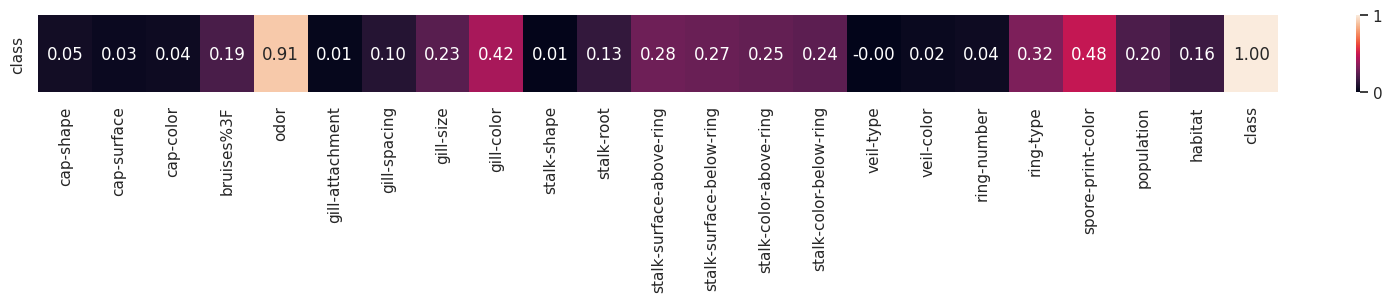

In [120]:
theilu = pd.DataFrame(index=['class'],columns=data.columns)
columns = data.columns
for j in range(0,len(columns)):
    u = theil_u(data['class'].tolist(),data[columns[j]].tolist())
    theilu.loc[:,columns[j]] = u
theilu.fillna(value=np.nan,inplace=True)
# Explicitly convert the DataFrame to numeric types for plotting
theilu = theilu.apply(pd.to_numeric, errors='coerce')
plt.figure(figsize=(20,1))
sns.heatmap(theilu,annot=True,fmt='.2f')
plt.show()

머신러닝 기법을 정확도(세로축)와 해석 가능성(가로축) 기준으로 비교한 것으로 왼쪽 위의 신경망, 앙상블, 커널 기반 방법은 정확도가 높지만 해석이 어렵고, 오른쪽 아래의 로지스틱 회귀는 해석이 쉽지만 상대적으로 단순하며 의사결정트리나 K-NN은 그 중간 정도의 위치에 있음

### 정확도가 높아질수록 모델 해석은 어려워지는 경향이 있다는 내용

<img src="https://miro.medium.com/v2/resize:fit:1400/1*3yNsE9wQ1CtV0WlaD5MgrA.jpeg">

## 6. SHAP (Shapley value additivity model)

- [Shapley_value](https://en.wikipedia.org/wiki/Shapley_value)
- [SHAP_github](https://github.com/slundberg/shap)
- [SHAP_site](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/scatter.html)
- [kaggle](https://www.kaggle.com/dansbecker/advanced-uses-of-shap-values)

### 🎮 SHAP 관점에서의 핵심 비유 (Game Theory)

- **Game (게임)**  
  → 모델의 예측 결과를 만들어내는 과정

- **Players (플레이어)**  
  → 모델에 입력되는 각 Feature (예: Age, Gender, Job)

- **Shapley Value의 역할**  
  → 각 Feature가 예측 결과에 얼마나 기여했는지를 정량적으로 측정

---

### ⚙️ 핵심 아이디어

- 각 Feature는 **게임에 참여하는 플레이어**
- 모델의 예측값은 **게임의 최종 결과(보상)**
- SHAP은  
  → 각 플레이어가 결과에 얼마나 기여했는지를 **공정하게 분배**

---

### 🎯 한 줄 정리

> **SHAP = "모델 예측이라는 게임에서 각 Feature의 공정한 기여도 분배 방법"**
<img src='https://miro.medium.com/max/1540/1*wOLS6BO2vGTSB4sCoAb6fQ.png'>

## **📌 1. SHAP 계산을 위한 모델 설정 (핵심 개념)**

- 동일한 데이터로 **8개의 선형회귀 모델**을 학습했다고 가정  
- 각 모델은 **서로 다른 Feature 조합(부분집합)** 을 사용

---

### ⚙️ 분석 대상

- 새로운 데이터 포인트: $x_0$
- 목표:
  → 각 모델이 $x_0$에 대해 **어떤 예측값을 내는지 비교**

---

### 📊 모델 구조 해석

- 각 모델은 다음을 의미:
  1. **사용된 Feature 조합 (Coalition)**
  2. 해당 조합으로 예측한 **결과값 (Prediction)**

👉 즉,  
- Feature의 부분집합마다 하나의 모델이 존재  
- 총 Feature가 3개라면 → $2^3 = 8$개의 모델

---

### 🎯 SHAP과의 연결

- SHAP은 이 8개 모델을 활용해서  
  → 특정 Feature가 추가될 때의 **예측 변화량(기여도)** 계산

- 다양한 조합에서의 변화를 평균내어  
  → **공정한 기여도(Shapley Value)** 산출

---

### ✅ 한 줄 정리

> **모든 Feature 조합으로 만든 모델들의 예측 차이를 기반으로 SHAP 값이 계산된다**

## **📌 2. SHAP Value for Age (핵심 요약)**

**정의**  
- $SHAP_{Age}(x_0)$: 특정 데이터 $x_0$에서 **Age 변수의 기여도**
- 핵심 개념:  
  → *Age가 추가될 때마다 예측값이 얼마나 변하는지(한계 기여도)를 평균낸 값*

---

### ⚙️ 계산 구조

- 한계 기여도:
$$
MC_{Age, S}(x_0) = f(S \cup \{Age\}) - f(S)
$$

- 전체 SHAP 값:
$$
SHAP_{Age}(x_0)
= \frac{1}{3}(-10k)
+ \frac{1}{6}(-9k)
+ \frac{1}{6}(-15k)
+ \frac{1}{3}(-12k)
$$

---

### 📊 각 항의 의미

| 상황 (S) | 의미 | 변화량 | 가중치 |
|----------|------|--------|--------|
| ∅ (아무 정보 없음) | Age가 처음 추가 | -10k | 1/3 |
| {Gender} | Gender 이후 Age 추가 | -9k | 1/6 |
| {Job} | Job 이후 Age 추가 | -15k | 1/6 |
| {Gender, Job} | 마지막으로 Age 추가 | -12k | 1/3 |

---

### 🎯 핵심 해석

- SHAP 값 =  
  **"Age가 들어가는 모든 경우에서의 영향력을 공정하게 평균낸 값"**
- 순서(조합)에 따라 달라지는 영향을 모두 반영
- → 특정 변수의 **공정한 기여도 측정 방법**

---

### ✅ 한 줄 정리

> **SHAP = "모든 가능한 순서에서의 한계 기여도의 가중 평균"**

### 📊 SHAP 결과 요약

- $SHAP_{Age}(x_0) = -11.33k$
- $SHAP_{Gender}(x_0) = -2.33k$
- $SHAP_{Job}(x_0) = +46.66k$

👉 해석  
- **Age, Gender** → 예측값을 감소시키는 방향으로 기여  
- **Job** → 예측값을 크게 증가시키는 핵심 변수  

---

### 🔄 머신러닝 vs 게임이론 대응 관계

| Machine Learning | Game Theory |
|------------------|------------|
| Features (특성) | Agents (플레이어) |
| Target의 분산 | Payoffs (보상) |
| Feature Importance | Fair Cost (공정한 기여도 분배) |

---

### 🎯 핵심 해석

- 모델 예측값 = 여러 Feature가 협력한 결과  
- SHAP은 이를 **게임이론 관점으로 변환**하여  
  → 각 Feature의 기여도를 **공정하게 분배**

---

### ✅ 한 줄 정리

> **SHAP 값 = 각 Feature가 예측 결과(보상)에 기여한 공정한 몫**

### 1. [Basic SHAP Interaction Value Example in XGBoost](https://shap.readthedocs.io/en/latest/example_notebooks/tabular_examples/tree_based_models/Basic%20SHAP%20Interaction%20Value%20Example%20in%20XGBoost.html)

In [121]:
import numpy as np
import xgboost
from sklearn.linear_model import LinearRegression

import shap

In [133]:
# 서로 아무런 상관관계가 없는 3개의 독립 변수를 만들고, 모델이 학습하기 좋게 평균을 0으로 맞춘 상태
N = 2_000
X = np.zeros((N, 5))

X[:1_000, 0] = 1

X[:500, 1] = 1
X[1_000:1_500, 1] = 1

X[:250, 2] = 1
X[500:750, 2] = 1
X[1_000:1_250, 2] = 1
X[1_500:1_750, 2] = 1

print(f"mean-center 전 각 컬럼의 평균 : {X.mean(axis=0)}")

# mean-center the data
X[:, 0:3] -= 0.5

y = 2 * X[:, 0] - 3 * X[:, 1]

mean-center 전 각 컬럼의 평균 : [0.5 0.5 0.5 0.  0. ]


In [130]:
# X0, X1, X2 변수는 0과 1이 정확히 반반씩 섞인 데이터를 평균 중심화(-0.5, 0.5)하면 분산은 정확히 0.5^2 = 0.25
# X3, X4 변수는 모두 0 이라 공분산과 분산 0
np.cov(X.T)

array([[0.25012506, 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.25012506, 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.25012506, 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ]])

In [131]:
X.mean(axis=0) #mean-center the data

array([0., 0., 0., 0., 0.])

In [127]:
# train a model with single tree
Xd = xgboost.DMatrix(X, label=y)
model = xgboost.train({"eta": 1, "max_depth": 3, "base_score": 0, "lambda": 0}, Xd, 1)

print("Model error =", np.linalg.norm(y - model.predict(Xd)))
print(model.get_dump(with_stats=True)[0])

Model error = 0.0
0:[f1<0.5] yes=1,no=2,missing=2,gain=4500,cover=2000
	1:[f0<0.5] yes=3,no=4,missing=4,gain=1000,cover=1000
		3:leaf=0.5,cover=500
		4:leaf=2.5,cover=500
	2:[f0<0.5] yes=5,no=6,missing=6,gain=1000,cover=1000
		5:leaf=-2.5,cover=500
		6:leaf=-0.5,cover=500



In [128]:
pred = model.predict(Xd, output_margin=True)

explainer = shap.TreeExplainer(model)
explanation = explainer(Xd)

shap_values = explanation.values
# make sure the SHAP values add up to marginal predictions
np.abs(shap_values.sum(axis=1) + explanation.base_values - pred).max()

np.float32(0.0)

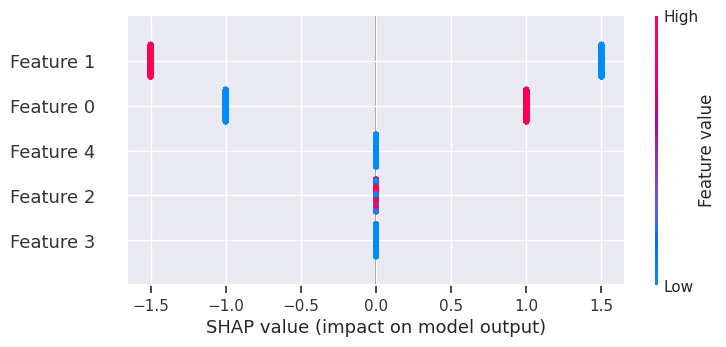

In [129]:
shap.plots.beeswarm(explanation)

### 📊 SHAP 해석 (선형모델: $y = 2X_0 - 3X_1$)

#### 🔴 Feature 1 ($-3X_1$)

- **가장 높은 중요도**
  → SHAP 범위: $[-1.5, 1.5]$

- **반비례 관계**
  - $X_1 = 0.5$ → SHAP = $-1.5$  ($0.5 \times -3$)
  - $X_1 = -0.5$ → SHAP = $+1.5$ ($-0.5 \times -3$)

- **해석**
  → 값이 커질수록 예측값은 감소  
  → 모델에서 가장 큰 영향력을 가지는 변수

---

### 🔵 Feature 0 ($2X_0$)

- **두 번째 중요도**
  → SHAP 범위: $[-1.0, 1.0]$

- **정비례 관계**
  - $X_0 = 0.5$ → SHAP = $+1.0$ ($0.5 \times 2$)
  - $X_0 = -0.5$ → SHAP = $-1.0$ ($-0.5 \times 2$)

- **해석**
  → 값이 커질수록 예측값도 증가  
  → $X_1$보다 영향력은 작지만 방향성은 동일

---

### ⚪ Feature 2, 3, 4 (모델 미포함 변수)

- **중요도 없음** → SHAP 값 = 0 (모든 점이 중앙에 위치)

- **해석** → 모델에 포함되지 않았기 때문에 예측에 기여하지 않음

---

### 🎯 핵심 결론

- SHAP은 선형 모델에서 → **계수 × 입력값 = 기여도**를 정확히 복원

- 독립 변수(공분산 = 0) 환경에서는 → 변수 간 영향 전이가 발생하지 않음

- 결과적으로:
$$
\text{SHAP 값} = \text{계수} \times \text{입력값}
$$

- 실제 값과 완벽히 일치:
  - $-3 \times 0.5 = -1.5$
  - $2 \times 0.5 = 1.0$

---

### ✅ 한 줄 정리

> **독립 변수 환경에서는 SHAP = 선형회귀 계수를 그대로 기여도로 변환한 값**

# 4.1  회귀생성 모델(Regression)

In [134]:
import xgboost
import shap
from sklearn.datasets import load_diabetes # Import load_diabetes from sklearn
# train an XGBoost model
X, y = load_diabetes(return_X_y=True) # Load data using sklearn
X = pd.DataFrame(X, columns=[f'feature_{i}' for i in range(X.shape[1])]) # Convert to DataFrame if needed
X.head()
y[0:10]

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310.])

In [152]:
model = xgboost.XGBRegressor().fit(X, y)
explainer = shap.Explainer(model) # explainer = shap.Explainer(model, X)
shap_values = explainer(X)
shap_values[0]

.values =
array([  3.4068007 ,  -4.649338  ,  16.406496  ,   0.58171266,
        -2.7278857 ,  -8.326876  ,  -2.6436841 ,  -5.917221  ,
        18.335064  , -15.348404  ], dtype=float32)

.base_values =
np.float32(152.13225)

.data =
array([ 0.03807591,  0.05068012,  0.06169621,  0.02187239, -0.0442235 ,
       -0.03482076, -0.04340085, -0.00259226,  0.01990749, -0.01764613])

In [153]:
np.mean(model.predict(X)) # 모델의 예측 값
model.predict(X)[0] # 모델 예측 값의 평균

np.float32(152.13225)

np.float32(151.24892)

## 1. 개별 자료의 예측 SHAP Value 시각화
### 1.1 폭포형태(waterfall)
- 입력변수의 색깔 : red는 양의 영향, blue는 음의 방향으로 영향
- 입력변수의 색깔의 길이 : red는 양의 영향 크기, blue는 음의 방향으로 영향 크기
- 첫번째 iinstance의 모델 예측 값 24.019, (f(x))와 모델 예측 평균 22.243, (E[f(X)])

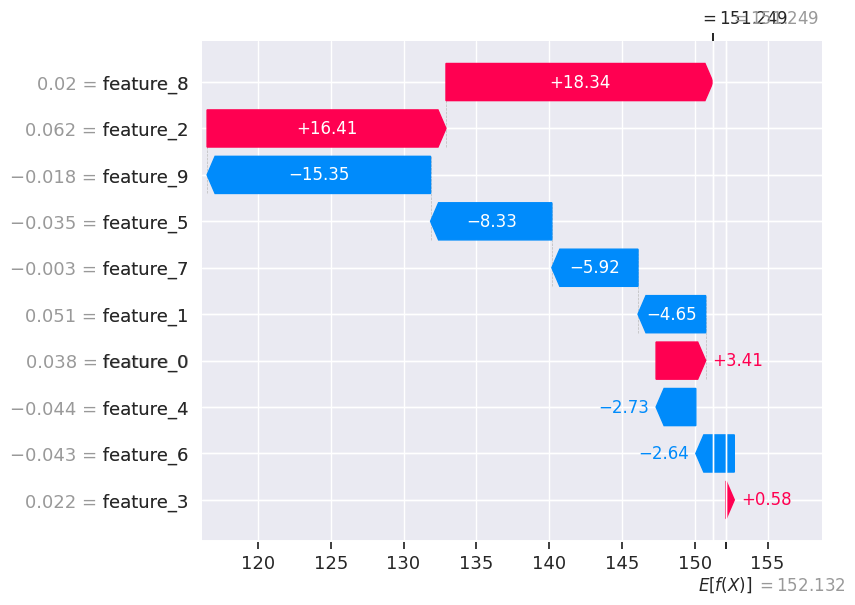

In [154]:
shap.plots.waterfall(shap_values[0])

### 2. 수평선 형태
- deeplearning의 경우 DeepExplainer를 적용하면 가능

#### Use Case
- SHAP provides multiple explainers for different kind of models.
     * TreeExplainer: Support XGBoost, LightGBM, CatBoost and scikit-learn models by Tree SHAP.
     * DeepExplainer (DEEP SHAP): Support TensorFlow and Keras models by using DeepLIFT and Shapley values.
     * GradientExplainer: Support TensorFlow and Keras models.
     * KernelExplainer (Kernel SHAP): Applying to any models by using LIME and Shapley values.

In [138]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)
shap_values[0]
shap.initjs()
shap.plots.force(explainer.expected_value, shap_values[0])

array([  3.4068007 ,  -4.649338  ,  16.406496  ,   0.58171266,
        -2.7278857 ,  -8.326876  ,  -2.6436841 ,  -5.917221  ,
        18.335064  , -15.348404  ], dtype=float32)

## 2. 전체 자료(특성변수)의 SHAP value 시각화

If we take many force plot explanations such as the one shown above, rotate them 90 degrees, and then stack them horizontally, we can see explanations for an entire dataset (in the notebook this plot is interactive):

In [143]:
shap.force_plot(explainer.expected_value, shap_values) # shap.force_plot(explainer.expected_value, shap_values, X)

In [144]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values) # shap.force_plot(explainer.expected_value, shap_values, X)

Visualize the sub set of dataset

In [146]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[:1,:])
shap_values[:1,:]; X.iloc[:1,:]

array([[  3.4068007 ,  -4.649338  ,  16.406496  ,   0.58171266,
         -2.7278857 ,  -8.326876  ,  -2.6436841 ,  -5.917221  ,
         18.335064  , -15.348404  ]], dtype=float32)

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9
0,0.038076,0.05068,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646


In [147]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[88:89,:], X.iloc[88:89,:])
shap_values[88:89,:]; X.iloc[88:89,:]

array([[ -6.630936 ,  -8.244375 , -26.504068 , -13.203064 ,  -4.5061045,
          0.1968285, -11.6154995,  -3.0743432, -41.486652 ,   4.9208674]],
      dtype=float32)

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9
88,-0.052738,0.05068,-0.040696,-0.067642,-0.03184,-0.037013,0.037595,-0.039493,-0.034522,0.069338


In [148]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[:89,:], X.iloc[:89,:])

### 모든 데이터(features, targets)의 SHAP value

In [149]:
data = pd.DataFrame(shap_values, columns = X.columns)
data['SUM'] = data.sum(1)  # 특성 변수의 SHAP values
data['f(x)'] = model.predict(X)
data['E[f(x)]'] = np.mean(model.predict(X))
data['SUM + E[f(x)]'] = data['SUM'] + data['E[f(x)]']
data

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,SUM,f(x),E[f(x)],SUM + E[f(x)]
0,3.406801,-4.649338,16.406496,0.581713,-2.727886,-8.326876,-2.643684,-5.917221,18.335064,-15.348404,-0.883335,151.248917,152.132248,151.248917
1,-7.740106,7.786335,-16.840137,-3.320134,-2.093042,-0.891601,-16.393509,-1.243583,-36.341606,-0.205837,-77.283211,74.848961,152.132248,74.849037
2,8.416444,-4.295445,-4.808689,-12.768341,-3.756814,-0.238016,5.777825,-1.229684,9.777622,-7.687283,-10.812382,141.319809,152.132248,141.319870
3,-3.197221,8.485053,-0.974748,-1.012747,-0.166981,1.359011,9.170012,-1.307772,39.193726,2.287892,53.836224,205.968445,152.132248,205.968475
4,-0.775831,9.968431,-26.996836,6.215810,0.093652,2.409791,6.202170,-0.426349,-15.713074,1.528266,-17.493969,134.638229,152.132248,134.638275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
437,-2.220894,-4.915186,23.303976,6.197274,-0.742491,-6.580296,-1.242593,-2.016418,28.979349,-14.042980,26.719742,178.852066,152.132248,178.851990
438,-8.147854,-4.842783,-15.474833,-8.695495,1.236676,-5.017255,9.570595,0.381694,-21.129040,4.046580,-48.071712,104.060547,152.132248,104.060532
439,12.015179,-10.127340,-13.465334,3.239348,3.050344,4.282777,9.123172,0.772283,-32.152504,2.969418,-20.292658,131.839569,152.132248,131.839584
440,2.419140,2.552580,19.577024,-8.469940,5.440277,10.179085,5.871908,1.171082,31.050583,-1.820317,67.971420,220.103607,152.132248,220.103668


### shap.plots.waterfall(shap_values[0])의 평균값 + 각 Features의 shap value를 모두 더하면

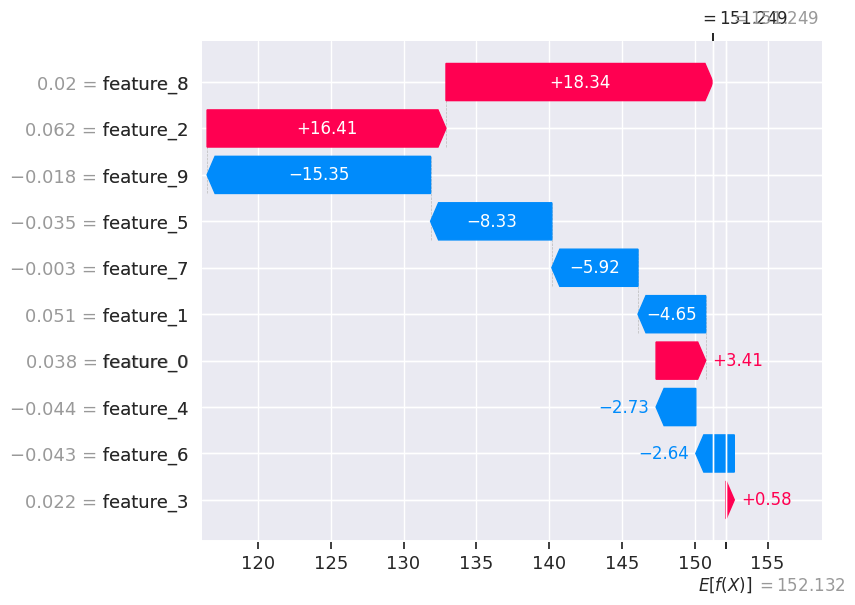

In [155]:
shap.plots.waterfall(shap_values[0])

### SHAP summary plot 해석하기

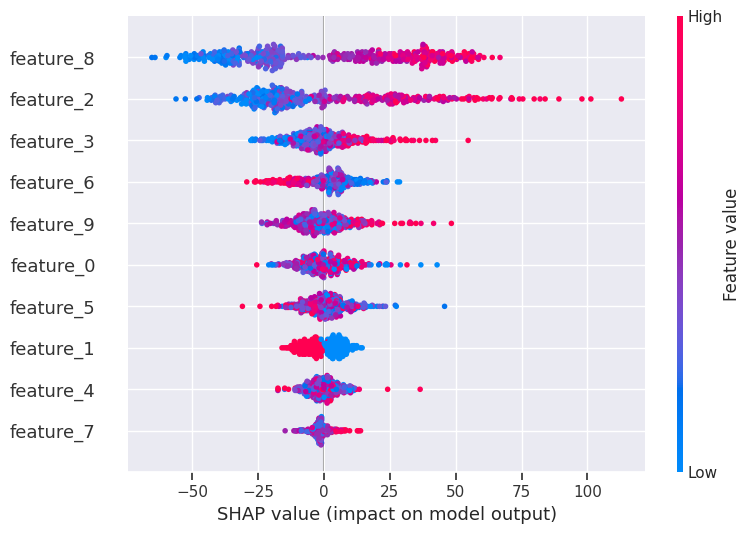

In [156]:
shap.summary_plot(shap_values, X)

### 📊 SHAP Summary Plot 해석 (핵심 요약)

---

#### 🔴 1. 가장 중요한 특성 (Top Features)

- **feature_8 (최대 영향력)**
  - 값 ↑ → 예측값 ↑ (정비례)
  - SHAP 범위가 가장 큼 (약 -60 ~ +60)
  - 👉 모델을 지배하는 핵심 변수

- **feature_2**
  - 정비례 관계
  - 일부 큰 양의 SHAP 값 → **이상치 영향 존재**
  - 👉 특정 샘플에서 예측값을 급격히 증가시킴

---

#### 🟡 2. 중간 영향력 특성

- **정비례 그룹**
  - feature_3, feature_9  
  → 값 ↑ → 예측값 ↑ (완만한 영향)

- **반비례 그룹**
  - feature_6, feature_0, feature_5  
  → 값 ↑ → 예측값 ↓

---

#### 🟣 3. 독특한 패턴

- **feature_1**
  - 명확한 양극화 (이분화된 분포)
  - 값 ↑ → 항상 예측값 ↓
  - 값 ↓ → 항상 예측값 ↑
  - 👉 **이진 변수(Binary)** 또는 임계값 기반 변수 가능성 높음

---

#### ⚪ 4. 영향 거의 없음

- **feature_4, feature_7**
  - SHAP ≈ 0에 집중
  - 👉 모델에 거의 기여하지 않음 (제거 후보)

---

#### 🎯 종합 해석

- **예측값 증가 요인**
  → feature_8, feature_2 (특히 높은 값)

- **예측값 감소 요인**
  → feature_1, feature_6 (높은 값)

- **데이터 특징**
  - feature_2: 이상치 영향 존재
  - feature_1: 범주형/이진 변수 가능성

---

### ✅ 한 줄 정리

> **SHAP은 어떤 변수가 예측을 올리고/내리는지 + 그 영향력의 크기를 직관적으로 보여준다**

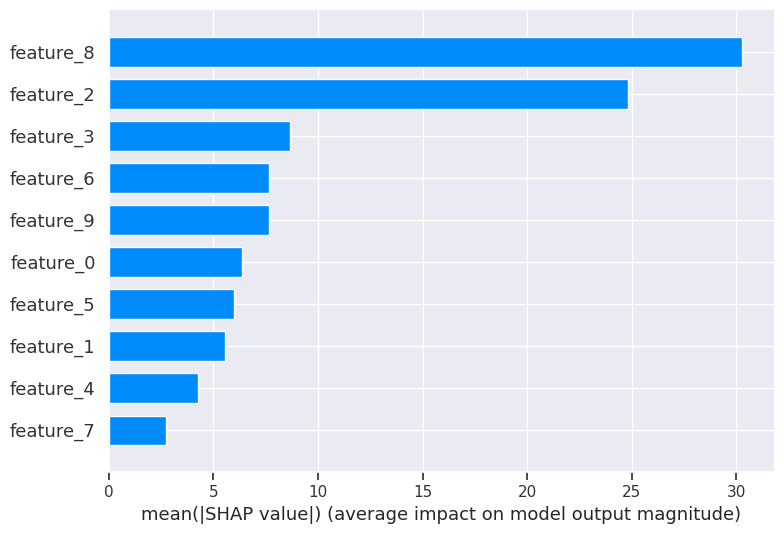

In [157]:
shap.summary_plot(shap_values, X, plot_type="bar")

# 4.2  분류 모델(Classification)
https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/scatter.html (그림그리기는 여기를)

The classic UCI adult income dataset (which is a classification task to predict if people made over \$50k in the 90s).

In [158]:
X,y = shap.datasets.adult()
y = pd.DataFrame(y, columns=['target'])
X.head()
X.shape
y.head()

,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7,13.0,4,1,0,4,1,2174.0,0.0,40.0,39
1,50.0,6,13.0,2,4,4,4,1,0.0,0.0,13.0,39
2,38.0,4,9.0,0,6,0,4,1,0.0,0.0,40.0,39
3,53.0,4,7.0,2,6,4,2,1,0.0,0.0,40.0,39
4,28.0,4,13.0,2,10,5,2,0,0.0,0.0,40.0,5


(32561, 12)

,target
0,False
1,False
2,False
3,False
4,False


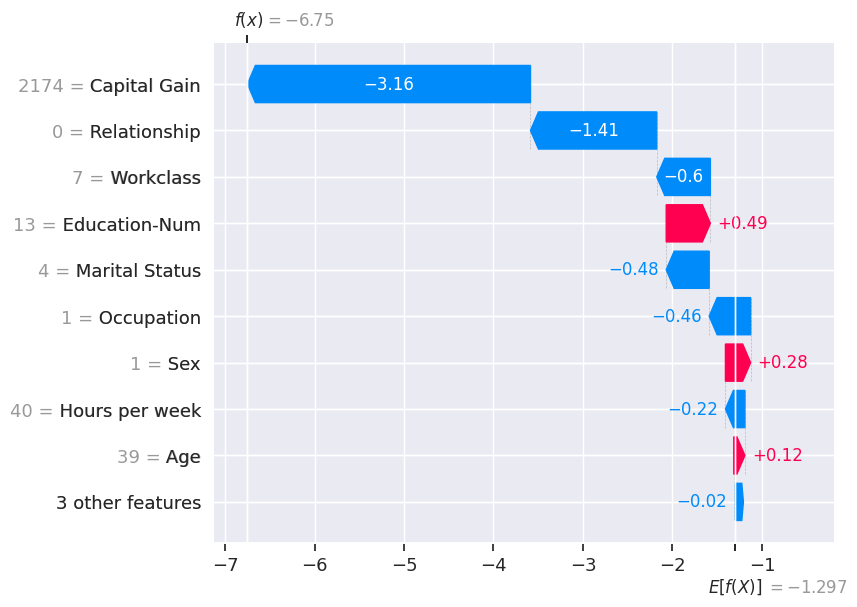

In [168]:
model = xgboost.XGBClassifier(eval_metric='mlogloss').fit(X, y)
explainer = shap.Explainer(model) # explainer = shap.Explainer(model, X)
shap_values = explainer(X)
shap.plots.waterfall(shap_values[0])

### 📊 SHAP Force Plot 해석 (개별 예측 설명)

---

#### 🔍 1. 기준값 vs 최종 예측

- **Base Value**
  $$
  E[f(X)] = -1.297
  $$
  → 전체 데이터 기준 평균 예측값

- **Prediction**
  $$
  f(x) = -6.75
  $$
  → 평균보다 크게 낮아짐 → **False (소득 ≤ 50K)**

---

### ⚙️ 2. 변수별 기여도

#### 🔵 예측을 낮춘 요인 (False 방향)

- **Capital Gain (2174.0)**   → 가장 큰 영향 ($-3.16$)

- **Relationship (0)**  → 두 번째 영향 ($-1.41$)

- **Workclass, Occupation**  → 추가적인 하락 요인

👉 핵심:  
**부정적 요인들이 강하게 작용하여 예측값을 크게 낮춤**

---

#### 🔴 예측을 높인 요인 (True 방향)

- **Education-Num (13.0)**  → $+0.49$ (높은 학력)

- **Sex, Age (39.0)**  → 소득 증가 방향으로 기여

👉 핵심:  
**긍정적 요인은 존재하지만 영향력이 상대적으로 작음**

---

### 🎯 3. 종합 해석

- 상승 요인: → 학력, 나이

- 하락 요인: → Capital Gain, Relationship, 직업 관련 변수

- 결과:
  → **하락 요인의 영향 > 상승 요인**

---

### 📌 최종 결론

> **긍정적 요소(학력, 나이)보다 부정적 요소(자산, 관계, 직업)가 더 크게 작용하여 False로 분류됨**

---

### 💡 해석 포인트

- SHAP은 모델의 의사결정 기준을 그대로 드러냄
- 값 단위가 **Log-odds** 라면  → 현재 결과는 **강한 부정 예측**을 의미
---

### ✅ 한 줄 정리

> **SHAP Force Plot은 “왜 이 예측이 나왔는가”를 변수별 영향으로 분해해서 보여준다**

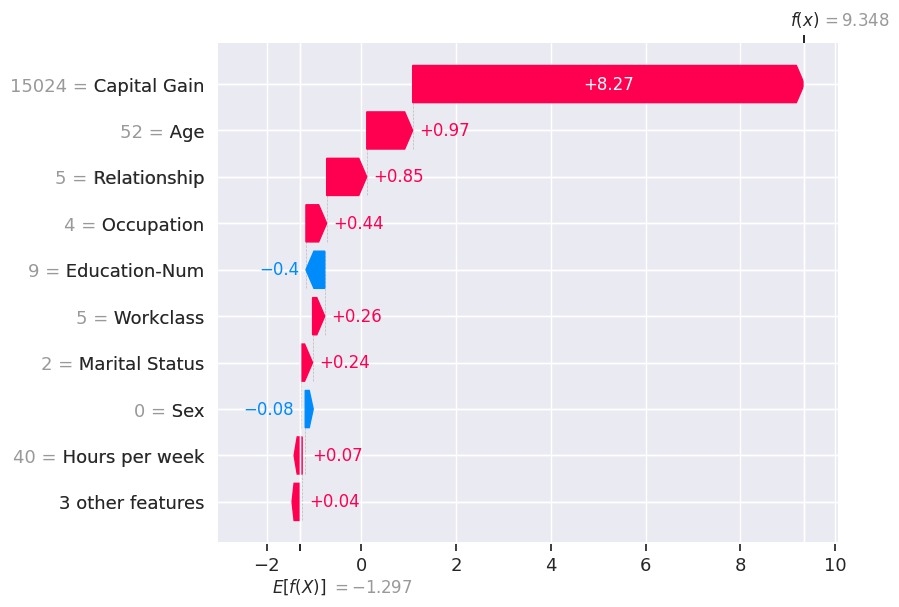

In [169]:
shap.plots.waterfall(shap_values[32560])

In [161]:
shap_values[0]

.values =
array([ 0.12434883, -0.59925145,  0.49357492, -0.48015672, -0.46350703,
       -1.4110292 ,  0.01406731,  0.28174502, -3.163397  , -0.06537072,
       -0.21756159,  0.03318328], dtype=float32)

.base_values =
np.float32(-1.296516)

.data =
array([3.900e+01, 7.000e+00, 1.300e+01, 4.000e+00, 1.000e+00, 0.000e+00,
       4.000e+00, 1.000e+00, 2.174e+03, 0.000e+00, 4.000e+01, 3.900e+01])

In [167]:
shap.initjs()
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X)
shap.force_plot(explainer.expected_value, shap_values[:89,:], X.iloc[:89,:])

In [163]:
data = pd.DataFrame(shap_values, columns = X.columns)
data['SUM'] = data.sum(1)  # 특성 변수의 SHAP values
data['f(x)'] = model.predict(X)
data['E[f(x)]'] = -1.4446166
data['SUM + E[f(x)]'] = data['SUM'] + data['E[f(x)]']
data.sample(10, random_state=111).iloc[:, 10:20]

,Hours per week,Country,SUM,f(x),E[f(x)],SUM + E[f(x)]
10636,-0.139360,0.019749,-0.629243,0,-1.444617,-2.073860
30981,-0.170992,0.018700,0.111827,0,-1.444617,-1.332790
28741,-0.849085,-0.411327,-1.703127,0,-1.444617,-3.147744
439,-0.026470,-0.006529,1.871702,1,-1.444617,0.427086
6046,-0.839514,0.023771,-3.797925,0,-1.444617,-5.242542
611,-0.169402,0.009286,-3.598059,0,-1.444617,-5.042676
1197,0.229409,0.000484,2.088609,1,-1.444617,0.643992
12367,-0.191370,-0.310762,-3.336185,0,-1.444617,-4.780801
20014,-0.059839,0.020960,2.679618,1,-1.444617,1.235002
7913,-0.161969,0.004648,-2.807319,0,-1.444617,-4.251935


<Axes: xlabel='f(x)', ylabel='SUM + E[f(x)]'>

-0.1480488023391724

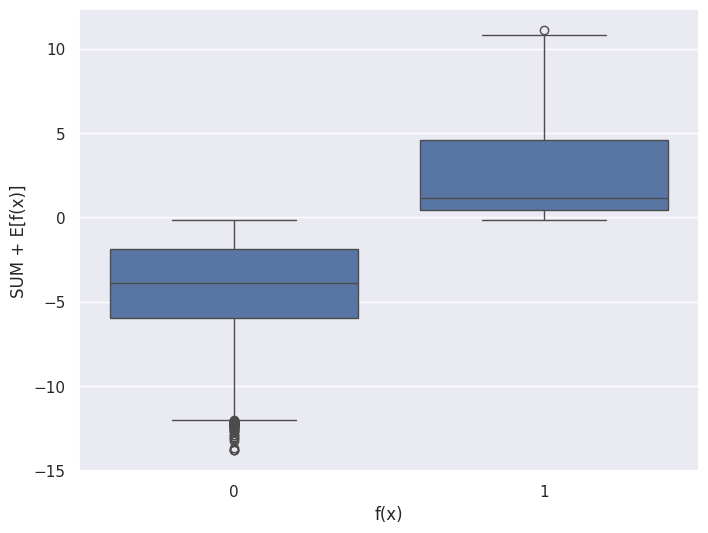

In [164]:
plt.rcParams['figure.figsize'] = (8,6)
sns.boxplot(x='f(x)', y='SUM + E[f(x)]', data=data)
data[data['f(x)'] == True]['SUM + E[f(x)]'].min()

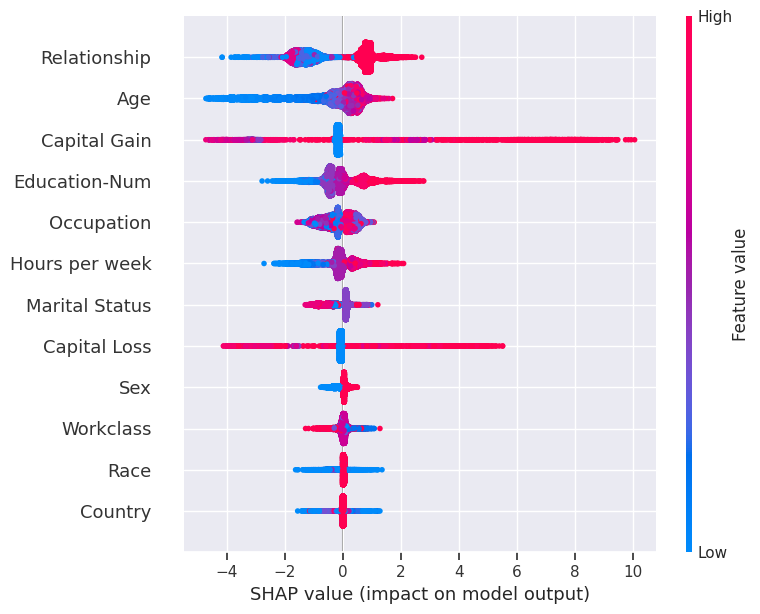

In [165]:
shap.summary_plot(shap_values, X)

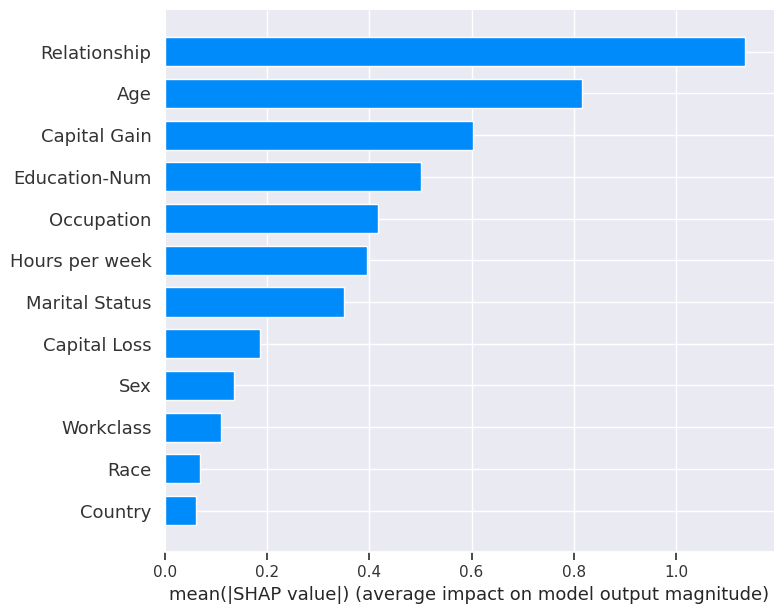

In [166]:
shap.summary_plot(shap_values, X, plot_type="bar")

### Simple dependence scatter plot
**의존성 산점도(Dependence scatter plot)** 는 단일 특성(Feature)이 모델의 예측 결과에 미치는 영향을 보여줍니다.

이 예제에서는 연봉 5만 달러($50k) 이상을 벌어들일 **로그 오즈(Log-odds)** 가 20세에서 40세 사이에서 눈에 띄게 증가합니다.

핵심 개념 설명

1. 의존성 산점도 (SHAP Dependence Plot)

> 단순히 "나이가 많으면 소득이 높다"는 상관관계를 넘어, 모델이 나이라는 변수 하나만을 떼어놓고 봤을 때 예측값(SHAP value)을 어떻게 변화시키는지 시각화한 것입니다.

2. 로그 오즈 (Log-odds)

> 의미: 확률을 수학적으로 다루기 쉽게 변환한 값입니다.

> 해석: SHAP 가로축의 단위가 로그 오즈라면, 값이 0보다 커질수록 연봉 5만 달러 이상일 확률이 급격히 높아짐을 의미합니다.

3. 20세~40세 구간의 의미

> 그래프상에서 이 구간의 기울기가 가파르다면, 모델은 **"사람이 사회 초년생에서 숙련공이 되는 이 시기에 소득 잠재력이 가장 폭발적으로 성장한다"** 고 학습했음을 보여줍니다. 40세 이후에는 이 그래프가 완만해지거나 정체될 가능성이 높습니다.

요약하자면: 이 시각화는 "나이"라는 단일 요인이 모델의 최종 판단(고소득 여부)에 어떤 곡선을 그리며 기여하는지 분석한 결과입니다. 40세까지의 가파른 상승 곡선이 모델 예측의 핵심 근거 중 하나라는 뜻이죠!

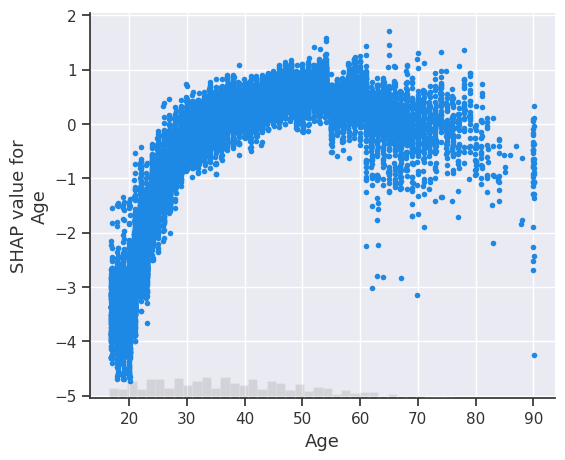

In [170]:
explainer = shap.Explainer(model) # explainer = shap.Explainer(model, X)
shap_values = explainer(X)
shap.plots.scatter(shap_values[:,"Age"])

💡 핵심 포인트 요약 (개조식)
- 점 하나 = 데이터 한 명: 그래프의 점 하나하나가 실제 사람 한 명의 데이터를 의미합니다.

- x축 = 실제 데이터: 예를 들어 '나이'라면 20세, 30세 등 실제 입력된 수치입니다.

- y축 = 기여도: "이 나이 덕분에(혹은 때문에) 고소득 확률이 얼마나 변했나?"를 보여줍니다.

- 회색 배경 = 밀도: 데이터가 특정 구간(예: 30대)에 얼마나 많이 몰려 있는지 보여주어 결과의 신뢰도를 판단하게 돕습니다.

- 이 설명은 아까 보신 "20세에서 40세 사이의 급격한 소득 증가" 그래프를 해석하는 구체적인 매뉴얼이라고 보시면 됩니다. 데이터 분포(회색 영역)가 두터운 곳에서 나오는 경향성일수록 통계적으로 더 믿을만하겠죠?

### Using color to highlight interaction effects

1. 핵심 내용 번역

> 상호작용 효과를 강조하기 위한 색상 활용

> 위 그래프에서 점들이 세로로 흩어져 있는 것(Vertical dispersion)은 같은 나이라도 사람마다 모델 예측에 미치는 영향이 다를 수 있음을 의미합니다. 이는 '나이'와 '다른 특성' 사이에 비선형적 상호작용이 존재한다는 증거입니다. (상호작용이 없다면 점들은 하나의 매끄러운 선 위에만 놓여야 합니다.)

> 어떤 특성이 이러한 상호작용을 일으키는지 확인하기 위해, 나이 산점도에 다른 특성의 값을 색상으로 입힐 수 있습니다.

> 색상 파라미터에 전체 Explanation 객체를 전달하면, 산점도는 자동으로 나이와 가장 강한 상호작용을 보이는 특성을 찾아내 색을 입힙니다. 만약 상호작용이 존재한다면, 색상별로 뚜렷한 세로 패턴이 나타나게 됩니다.

> 구체적 예시 해석

>> 아래 예시를 보면, 교육 수준이 높은 20대는 교육 수준이 낮은 20대보다 연봉 5만 달러 이상을 벌 확률이 더 낮게 나타납니다. 이는 '교육 수준(Education-Num)'과 '나이(Age)' 사이에 상호작용 효과가 있음을 시사합니다.

2. 핵심 개념 요약 (개조식)

> 세로로 퍼진 점들의 의미: 같은 x값(나이)인데 y값(SHAP)이 다르다면, 다른 변수가 끼어들어 영향을 주고 있다는 뜻입니다.

>>색상의 역할: "나이와 짝꿍이 되어 예측값을 흔드는 범인이 누구인가?"를 색깔로 보여줍니다.

>> 상호작용의 발견:  나이와 교육 수준의 상호작용 예시처럼, 특정 나이대에서 색깔별로 y값이 확연히 갈린다면 두 변수는 서로 엮여 있는 것입니다.

3. 왜 '고학력 20대'의 소득 예측이 더 낮을까요? (데이터의 이면)

> 이 예시에서 흥미로운 점은 **"교육을 많이 받은 20대가 왜 돈을 더 못 벌 것으로 예측되는가?"**입니다.

>> 현실적 해석: 교육 기간이 길다는 것은 20대 초반에 경제 활동 대신 **학업(대학원 등)**을 하고 있을 가능성이 높다는 뜻입니다. 반면, 교육 기간이 짧은 20대는 일찍부터 경력을 쌓아 수입이 생기기 시작했을 수 있습니다.

>> 모델의 논리: 모델은 단순히 "학력이 높으면 좋다"가 아니라, **"20대이면서 + 학력이 매우 높음 = 현재 학생일 확률이 높음 = 소득 낮음"**이라는 복합적인 논리(Interaction)를 찾아낸 것입니다.

이처럼 SHAP의 색상 기능을 활용하면 모델이 단순히 변수 하나하나를 따로 보는 것이 아니라, 변수들이 어떻게 조합되어 결과를 내는지 깊이 있게 이해할 수 있습니다.

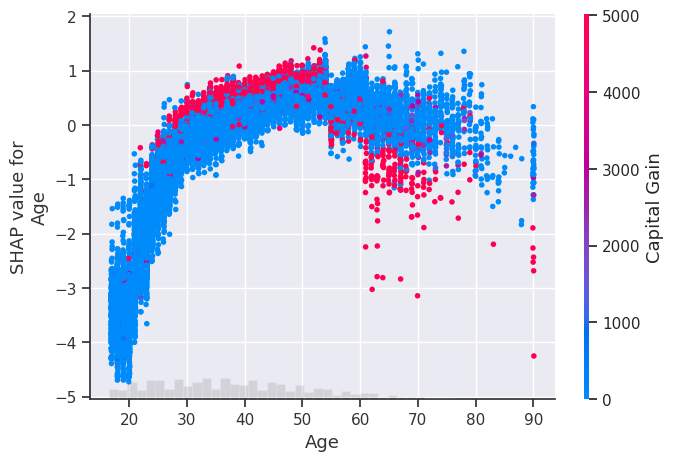

In [171]:
shap.plots.scatter(shap_values[:, "Age"], color=shap_values)

To explicitly control which feature is used for coloring you can pass a specific feature column to the color parameter.

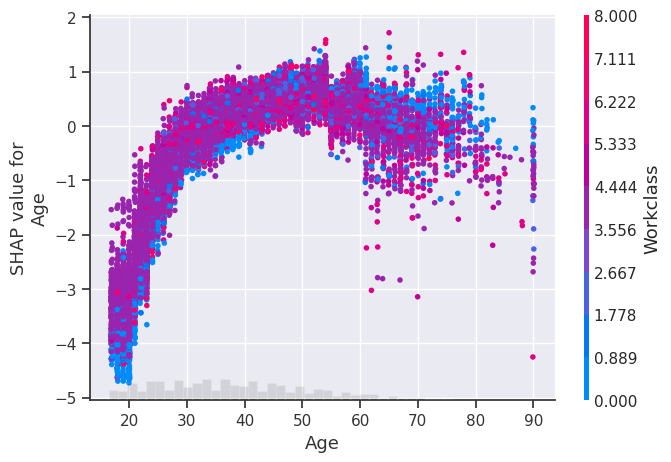

In [172]:
shap.plots.scatter(shap_values[:, "Age"], color=shap_values[:,"Workclass"])

In the plot above we see that the Workclass feature is encoded with a number for the sake of the XGBoost model. When plotting though we often would rather use the original string values before they were categorically encoded. To do this we can set the .display_data property of the Explanation object to a parallel version of the data we would like displayed in plots.

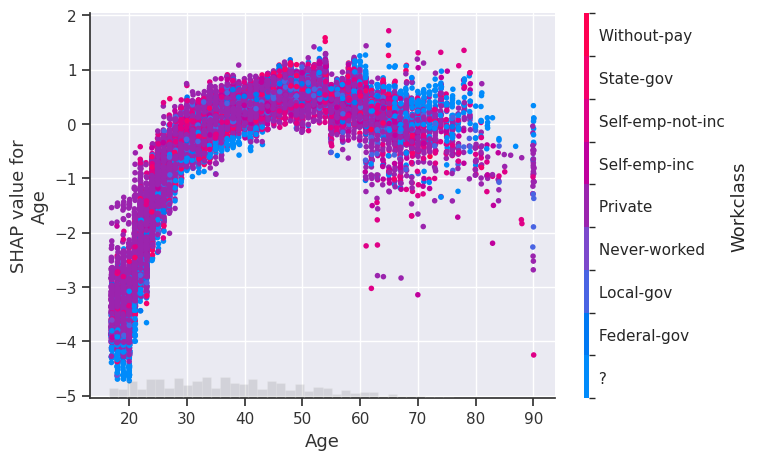

In [173]:
X_display,y = shap.datasets.adult(display=True)
shap_values.display_data = X_display.values

shap.plots.scatter(shap_values[:, "Age"], color=shap_values[:,"Workclass"])

### Exploring different interaction colorings
- we can use shap.approximate_interactions to guess which features may interact with age.
-  we can make plots colored by each of the top three possible interacting features

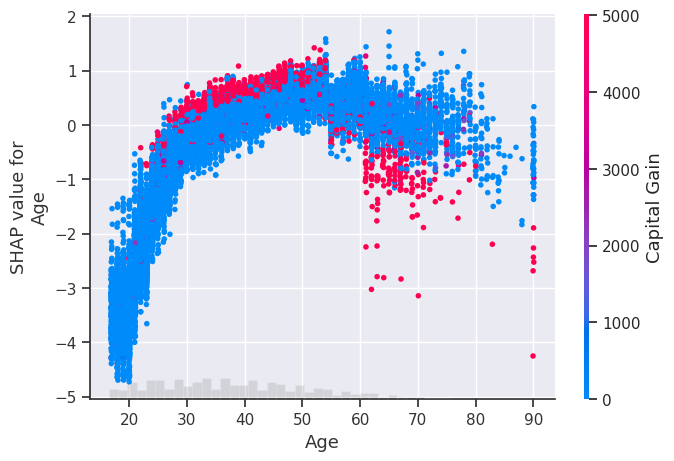

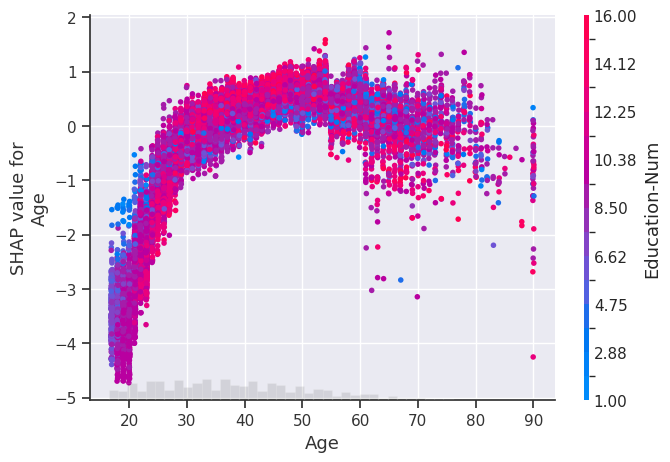

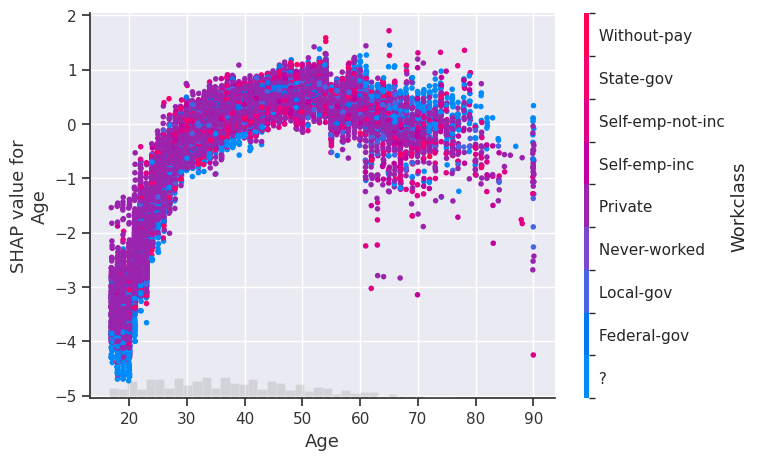

In [174]:
inds = shap.utils.potential_interactions(shap_values[:, "Age"], shap_values)
for i in range(3):
    shap.plots.scatter(shap_values[:,"Age"], color=shap_values[:,inds[i]])

### Using global feature importance orderings
Sometimes we don’t know the name or index of the feature we want to plot, we just want to plot the most important features. To do that we can use the dot-chaining capability of the Explanation object to compute a measure of global feature importance, sort by that measure (descending), and then pick out the top feature (which in this case is Age):

# End